# Florence-2 speed benchmark

<a href="https://colab.research.google.com/github/anyantudre/florence-2-cookbook/blob/main/7.%20Florence-2%20speed%20benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Few speed numbers have been published for Florence-2. This notebook measures how long each task takes, for both model sizes, in float32 and float16, with greedy decoding and with beam search (3 beams, the setting most examples use). It also measures peak GPU memory, and runs a few tasks on the CPU.

The saved outputs come from a laptop with an NVIDIA RTX 4070 Laptop GPU. Run the notebook on Colab to get the same tables for a T4: it detects the hardware and prints it. A summary of a Colab T4 run is at the end of the notebook.

In [ ]:
!pip install -q -U "transformers>=5.13"

In [1]:
import platform
import statistics
import time

import pandas as pd
import requests
import torch
import transformers
from PIL import Image
from transformers import AutoProcessor, Florence2ForConditionalGeneration

gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none"
print(f"GPU: {gpu}")
print(f"CPU: {platform.processor() or platform.machine()}")
print(f"torch {torch.__version__}, transformers {transformers.__version__}")

GPU: NVIDIA GeForce RTX 4070 Laptop GPU
CPU: AMD64 Family 26 Model 36 Stepping 0, AuthenticAMD
torch 2.12.0+cu126, transformers 5.22.1


## Test images and tasks

The car photo is used for every task except OCR, which uses a book cover. Each measurement is the median of 5 runs, after one warm-up run.

In [2]:
def load_image(url):
    return Image.open(requests.get(url, stream=True).raw).convert("RGB")


car = load_image("https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/car.jpg")
book = load_image("http://ecx.images-amazon.com/images/I/51UUzBDAMsL.jpg")

TASKS = [
    ("<CAPTION>", "", car),
    ("<DETAILED_CAPTION>", "", car),
    ("<MORE_DETAILED_CAPTION>", "", car),
    ("<OD>", "", car),
    ("<CAPTION_TO_PHRASE_GROUNDING>", "A green car parked in front of a yellow building.", car),
    ("<REFERRING_EXPRESSION_SEGMENTATION>", "a green car", car),
    ("<OCR>", "", book),
    ("<OCR_WITH_REGION>", "", book),
]
REPEATS = 5

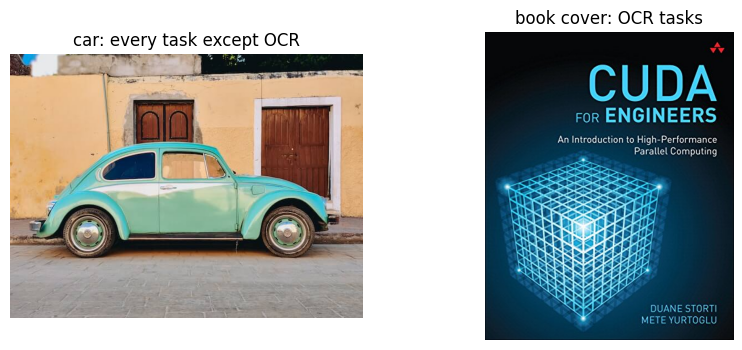

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (title, img) in zip(axes, [("car: every task except OCR", car), ("book cover: OCR tasks", book)]):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")
plt.show()

In [4]:
def sync(device):
    if device == "cuda":
        torch.cuda.synchronize()


def bench(model, processor, task, text_input, image, device, dtype, num_beams, repeats=REPEATS):
    inputs = processor(text=task + text_input, images=image, return_tensors="pt").to(device, dtype)

    def generate():
        with torch.inference_mode():
            return model.generate(**inputs, max_new_tokens=1024, num_beams=num_beams, do_sample=False)

    generate()  # warm-up
    times = []
    for _ in range(repeats):
        sync(device)
        start = time.perf_counter()
        ids = generate()
        sync(device)
        times.append(time.perf_counter() - start)
    seconds = statistics.median(times)
    tokens = ids.shape[1] - 1
    return {"latency_ms": round(seconds * 1000), "output_tokens": tokens, "tokens_per_s": round(tokens / seconds)}

## GPU

In [5]:
rows, memory = [], []
if torch.cuda.is_available():
    for size in ("base", "large"):
        model_id = f"florence-community/Florence-2-{size}"
        processor = AutoProcessor.from_pretrained(model_id)
        for dtype in (torch.float32, torch.float16):
            model = Florence2ForConditionalGeneration.from_pretrained(model_id, dtype=dtype).to("cuda").eval()
            torch.cuda.reset_peak_memory_stats()
            for num_beams in (1, 3):
                for task, text_input, image in TASKS:
                    result = bench(model, processor, task, text_input, image, "cuda", dtype, num_beams)
                    rows.append({"model": size, "dtype": str(dtype).replace("torch.", ""),
                                 "decoding": "greedy" if num_beams == 1 else "3 beams", "task": task, **result})
            memory.append({"model": size, "dtype": str(dtype).replace("torch.", ""),
                           "peak_memory_gb": round(torch.cuda.max_memory_allocated() / 1e9, 2)})
            del model
            torch.cuda.empty_cache()

gpu_results = pd.DataFrame(rows)
print(f"{len(gpu_results)} measurements on {gpu}")

64 measurements on NVIDIA GeForce RTX 4070 Laptop GPU


### Latency per task (milliseconds, median of 5 runs)

In [6]:
latency = gpu_results.pivot_table(index="task", columns=["model", "dtype", "decoding"], values="latency_ms")
latency = latency.reindex([t for t, _, _ in TASKS])
latency

model                                  base                            large  \
dtype                               float16         float32          float16   
decoding                            3 beams  greedy 3 beams  greedy  3 beams   
task                                                                           
<CAPTION>                             204.0   182.0   343.0   239.0    373.0   
<DETAILED_CAPTION>                    495.0   530.0   602.0   547.0    986.0   
<MORE_DETAILED_CAPTION>              1248.0   972.0  1321.0   963.0   2313.0   
<OD>                                  330.0   274.0   378.0   319.0    431.0   
<CAPTION_TO_PHRASE_GROUNDING>         254.0   216.0   396.0   257.0    505.0   
<REFERRING_EXPRESSION_SEGMENTATION>  9291.0  5514.0  7008.0  5062.0  10878.0   
<OCR>                                 445.0   345.0   544.0   363.0    916.0   
<OCR_WITH_REGION>                    1214.0   759.0  1241.0   891.0   1741.0   

model                                                         
dtype                                        float32          
decoding                             greedy  3 beams  greedy  
task                                                          
<CAPTION>                             485.0    780.0   741.0  
<DETAILED_CAPTION>                    759.0   1205.0   988.0  
<MORE_DETAILED_CAPTION>              1676.0   2637.0  2186.0  
<OD>                                  366.0    764.0   693.0  
<CAPTION_TO_PHRASE_GROUNDING>         371.0    861.0   696.0  
<REFERRING_EXPRESSION_SEGMENTATION>  9266.0  11046.0  9982.0  
<OCR>                                 706.0   1200.0  1025.0  
<OCR_WITH_REGION>                    1388.0   2382.0  1823.0

### Output length and throughput (float16, greedy)

In [7]:
fp16_greedy = gpu_results[(gpu_results.dtype == "float16") & (gpu_results.decoding == "greedy")]
fp16_greedy.pivot_table(index="task", columns="model", values=["output_tokens", "tokens_per_s"]).reindex([t for t, _, _ in TASKS])

output_tokens        tokens_per_s      
model                                        base  large         base large
task                                                                       
<CAPTION>                                    13.0   17.0         71.0  35.0
<DETAILED_CAPTION>                           42.0   35.0         79.0  46.0
<MORE_DETAILED_CAPTION>                      91.0  105.0         94.0  63.0
<OD>                                         22.0   15.0         80.0  41.0
<CAPTION_TO_PHRASE_GROUNDING>                16.0   16.0         74.0  43.0
<REFERRING_EXPRESSION_SEGMENTATION>         532.0  598.0         96.0  65.0
<OCR>                                        31.0   36.0         90.0  51.0
<OCR_WITH_REGION>                            78.0   78.0        103.0  56.0

### Peak GPU memory during the runs

In [8]:
pd.DataFrame(memory)

,model,dtype,peak_memory_gb
0,base,float32,1.18
1,base,float16,0.66
2,large,float32,3.58
3,large,float16,1.91


## CPU

A shorter run: the base model in float32 with greedy decoding, on three tasks, with 3 runs each.

In [9]:
cpu_rows = []
processor = AutoProcessor.from_pretrained("florence-community/Florence-2-base")
model = Florence2ForConditionalGeneration.from_pretrained("florence-community/Florence-2-base", dtype=torch.float32).eval()
for task, text_input, image in [TASKS[0], TASKS[3], TASKS[6]]:
    result = bench(model, processor, task, text_input, image, "cpu", torch.float32, num_beams=1, repeats=3)
    cpu_rows.append({"task": task, **result})
pd.DataFrame(cpu_rows)

,task,latency_ms,output_tokens,tokens_per_s
0,<CAPTION>,2014,13,6
1,<OD>,2272,22,10
2,<OCR>,2468,31,13


## Reading the results

From the saved run on an RTX 4070 Laptop GPU:

- Latency follows the length of the output. A caption (13 to 17 tokens) takes 0.2 to 0.5 s, while referring expression segmentation, which writes polygons as 530 to 600 location tokens, takes 5 to 11 s.
- Beam search with 3 beams was slower than greedy decoding in 30 of the 32 comparisons. The two exceptions may come from beam search producing a shorter answer, or from run-to-run variation, which is larger on a laptop GPU. Try greedy decoding first.
- float16 halves the memory (base: 1.18 to 0.66 GB, large: 3.58 to 1.91 GB). With greedy decoding it made large 1.3 to 1.9× faster; for base the gain was small, and two tasks were slightly slower.
- With float16 and greedy decoding, large was 1.3 to 2.7× slower than base, depending on the task.
- On the CPU, base in float32 takes about 2 to 2.5 s for a caption, detection or OCR.

Laptop GPUs change speed with power settings and temperature, so treat these numbers as a rough guide and rerun the notebook on your own hardware. The summary in [AWESOME.md](AWESOME.md) comes from this run.

## Results on a Colab T4

The same notebook, run on a free Colab T4 (torch 2.11, transformers 5.22.1). Latency in milliseconds, float16 with greedy decoding, next to the RTX 4070 Laptop GPU run above:

| Task | T4, base | T4, large | RTX 4070 Laptop, base | RTX 4070 Laptop, large |
|------|---------:|----------:|----------------------:|-----------------------:|
| `<CAPTION>` | 138 | 382 | 182 | 485 |
| `<DETAILED_CAPTION>` | 321 | 542 | 530 | 759 |
| `<MORE_DETAILED_CAPTION>` | 807 | 1,230 | 972 | 1,676 |
| `<OD>` | 191 | 371 | 274 | 366 |
| `<CAPTION_TO_PHRASE_GROUNDING>` | 151 | 332 | 216 | 371 |
| `<REFERRING_EXPRESSION_SEGMENTATION>` | 3,318 | 7,031 | 5,514 | 9,266 |
| `<OCR>` | 311 | 546 | 345 | 706 |
| `<OCR_WITH_REGION>` | 520 | 1,134 | 759 | 1,388 |

On the T4:

- The T4 was faster than the laptop GPU for most tasks.
- With float16 and greedy decoding, large was 1.5 to 2.8× slower than base.
- float16 was faster than float32 for every task with large, and for 7 of the 8 tasks with base.
- Beam search with 3 beams was slower than greedy decoding in 25 of the 32 comparisons, and took the same time in 2.
- Peak GPU memory was the same as on the laptop: 0.66 GB for base and 1.91 GB for large in float16.
- Colab's CPU took about 7 s per task with base in float32, against 2 to 2.5 s on the laptop CPU.